# 9. Rendering: POV-Ray and Blender

`plot_tree` is the right tool for looking at a cell. For a figure, or anything
that needs shadows, materials or a chosen camera, the toolbox hands the
morphology to a dedicated renderer. There are two routes, and they suit
different jobs:

| | `save_pov` (POV-Ray) | `pynetrees.blender` (Blender) |
|---|---|---|
| **What you get** | Plain-text scene files | Real, editable Blender objects, saved as a `.blend` |
| **Extra install** | Only the `povray` program, and only to render | The `bpy` module: about 300 MB, Python 3.11, `numpy < 2` |
| **Colour** | Any value per node | One colour per region |
| **Best for** | Scripted figures, colour-coding a measurement, handing someone a small file | Scenes you want to keep editing by hand: lighting, materials, animation |

## Setting up

POV-Ray is a separate program. `bpy` cannot share an environment with numpy 2,
so give this notebook its own environment, then select it as the kernel:

```bash
python3.11 -m venv .venv-blender
source .venv-blender/bin/activate
pip install -e ".[blender,plot,matlab,notebook]"

brew install povray        # macOS
# sudo apt install povray  # Debian / Ubuntu
```

Part 1 needs only POV-Ray, so it also runs in a normal numpy 2 environment.
Part 2 stops at its first cell if `bpy` is missing, and Part 3 needs both.

In [1]:
import math
import os
import shutil
import subprocess
import tempfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pynetrees as pt

# Scene files and individual renders go here. Point this at a real folder if
# you want to keep them; the .pov and .blend files are worth keeping.
WORK = Path(tempfile.mkdtemp(prefix="pynetrees_render_"))

tree = pt.sample_tree()   # 197 nodes: small enough to see each branch
hss = pt.hss_tree()       # 2252 nodes: a whole fly interneuron, with its axon


def panel(paths, titles, ncols=None, width=4.2, save=None):
    "Show rendered images side by side, optionally saving the figure."
    ncols = ncols or len(paths)
    nrows = math.ceil(len(paths) / ncols)
    first = plt.imread(paths[0])
    height = width * first.shape[0] / first.shape[1]
    fig, axes = plt.subplots(nrows, ncols, squeeze=False,
                             figsize=(width * ncols, (height + 0.3) * nrows))
    for ax in axes.flat:
        ax.axis("off")
    for ax, path, title in zip(axes.flat, paths, titles):
        ax.imshow(plt.imread(path))
        ax.set_title(title, fontsize=10)
    fig.tight_layout()
    if save:
        fig.savefig(save, dpi=110)
    plt.show()


print(tree)
print(hss)

Tree(name='sample', n_nodes=197, regions=[dendrite, subtree])
Tree(name='hss', n_nodes=2252, regions=[axon, dend, soma])


---

# Part 1: POV-Ray

POV-Ray renders from a text description of a scene. `save_pov` writes that
description, so exporting needs no renderer at all: only turning the text into
an image does.

## 1.1 What `save_pov` writes

Two files come out. `<name>.pov` declares the geometry and nothing else.
`sh<name>.pov` is a small scene that includes it and adds a camera, lights and
a background. Because they are separate, one morphology can be re-lit or dropped
into another scene without exporting it again.

The file name becomes a POV-Ray identifier, so it cannot be one of POV-Ray's
reserved words, such as `v` or `box`. `save_pov` raises an error if it is. Every
reserved word is lower-case, so a name containing a capital letter is always
safe.

In [2]:
geometry = pt.save_pov(tree, WORK / "Sample.pov", style="plain")
scene = geometry.with_name("sh" + geometry.name)

print(f"--- {geometry.name} ({geometry.stat().st_size / 1024:.0f} kB) ---")
print("\n".join(geometry.read_text().splitlines()[:5]))
print("   ...")
print(f"\n--- {scene.name} ---")
print(scene.read_text())

--- Sample.pov (17 kB) ---
// sample: 196 segments, written by pynetrees
#declare Sample = union {
  blob { threshold .15
    cylinder { <0.0000, 0.0000, 0.0000>, <9.6401, 4.2864, -4.3145>, 2.07620, 1 }
    cylinder { <9.6401, 4.2864, -4.3145>, <17.6676, 8.3241, -3.0645>, 2.08618, 1 }
   ...

--- shSample.pov ---
// black on white, no shading -- the one for a figure panel
// render:  povray +I{this file} +W1200 +H900 +A

#include "Sample.pov"
#include "colors.inc"

background { rgbt <1, 1, 1, 0> }

camera {
  right     x * image_width / image_height
  location  <57.0737, 44.2830, -4.3145 - 1.1 * max(114.1475, 115.6194 * image_width / image_height) / (2 * tan(radians(32.5)))>
  look_at   <57.0737, 44.2830, 15.5944>
  angle     65
}

light_source { <57.0737, 44.2830, -119.9339> color White shadowless }
object { Sample finish { ambient 1 } }



## 1.2 Rendering

From a terminal, a render is one command, run from the folder holding the files:

```bash
povray +IshSample.pov +W800 +H800 +A
```

`+A` turns on anti-aliasing. The helper below does the same from Python. It runs
in the scene's own folder because the `#include` is a relative path.

POV-Ray prints two warnings for these files, `Should have at least 2 objects in
csg` and `assumed_gamma not specified`. Both are harmless, so the helper only
shows POV-Ray's output when a render fails.

In [3]:
def povray(scene, width=800, height=800):
    "Render a POV-Ray scene to a PNG beside it, and return the PNG's path."
    scene = Path(scene)
    executable = shutil.which("povray")
    if executable is None:
        raise RuntimeError("POV-Ray is not on the PATH: see 'Setting up' above")
    image = scene.with_suffix(".png")
    result = subprocess.run(
        [executable, f"+I{scene.name}", f"+O{image.name}", f"+W{width}",
         f"+H{height}", "+FN", "+A", "-D"],     # +FN = PNG, -D = no preview window
        cwd=scene.parent, capture_output=True, text=True)
    if result.returncode != 0:
        raise RuntimeError(result.stderr[-1500:])
    return image

## 1.3 The three scene styles

`pt.POV_STYLES` holds the presets from MATLAB's `pov_tree`. Their camera works
out its distance when POV-Ray renders, so the whole cell stays in frame at any
image size, wherever the cell sits in space.

plain         black on white, no shading -- the one for a figure panel


fluorescence  glowing cell on black, as a confocal stack looks


coral         lit from above over a grey ground plane


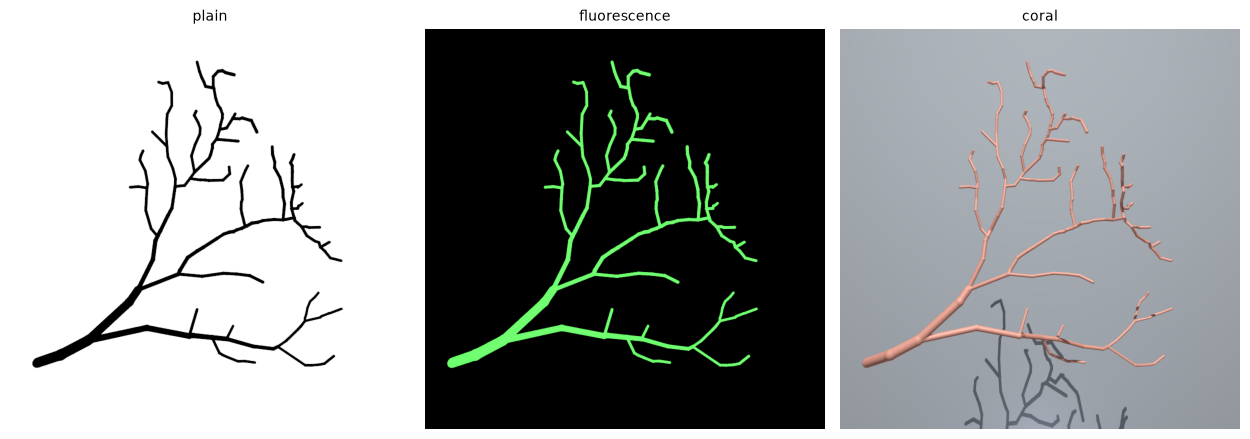

In [4]:
images = []
for style, (_, _, description) in pt.POV_STYLES.items():
    name = f"Sample_{style}"
    pt.save_pov(tree, WORK / f"{name}.pov", style=style, width=800, height=800)
    images.append(povray(WORK / f"sh{name}.pov"))
    print(f"{style:13s} {description}")

panel(images, list(pt.POV_STYLES), save="tut09_pov_styles.png")

## 1.4 Colour-coding a measurement

`v=` takes one value per node and writes its colour into each segment, mapped
through viridis. By default the scale runs from zero to the maximum;
`minmax=True` stretches it between the smallest and largest values. `nodes=`
restricts the export to part of the tree, and `color=` sets a single colour when
there is no `v`.

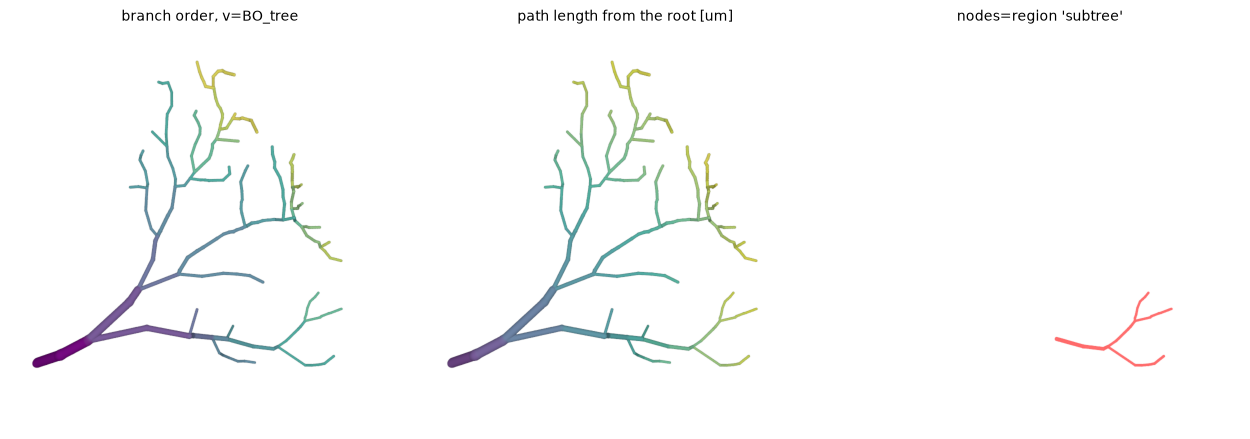

In [5]:
order = pt.BO_tree(tree)
path_length = pt.Pvec_tree(tree, pt.len_tree(tree))
subtree = tree.region_nodes("subtree")

pt.save_pov(tree, WORK / "Sample_order.pov", v=order, minmax=True)
pt.save_pov(tree, WORK / "Sample_path.pov", v=path_length)
pt.save_pov(tree, WORK / "Sample_part.pov", nodes=subtree, color=(0.8, 0.1, 0.1))

images = [povray(WORK / f"shSample_{n}.pov") for n in ("order", "path", "part")]
panel(images, ["branch order, v=BO_tree", "path length from the root [um]",
               "nodes=region 'subtree'"],
      save="tut09_pov_colour.png")

## 1.5 Blobs or cylinders

`blob=True`, the default, fuses the cylinders into one smooth surface. That
removes the seams at joints, but the surface sits inside the original cylinders,
so the cell is drawn thinner than it is. Use `blob=False` when the thickness in
the picture matters. The numbers below show how much is lost on this cell.

image covered by the cell: blob 4.16%, cylinders 5.24%


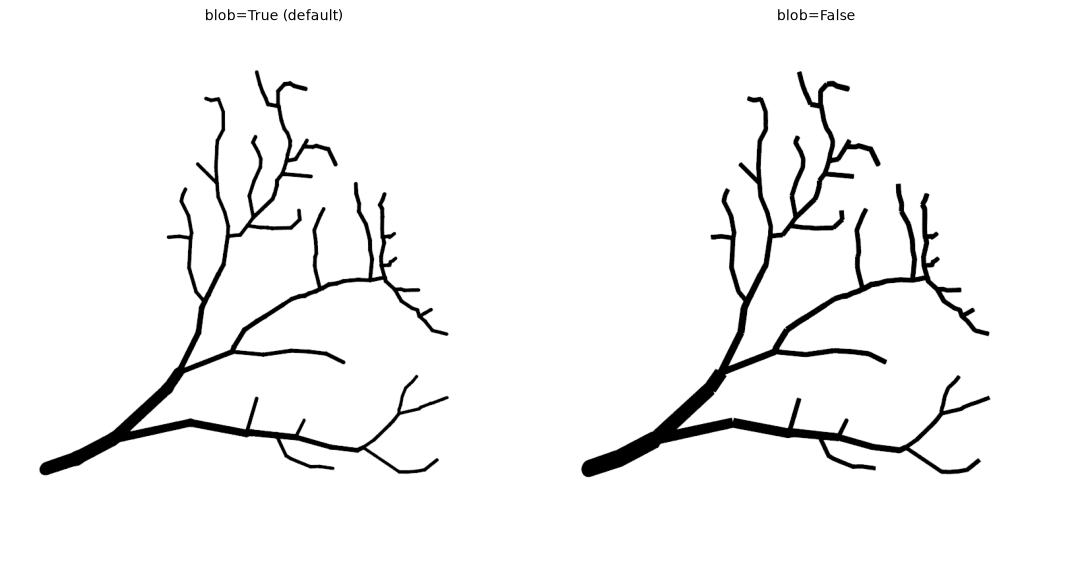

In [6]:
images, ink = [], {}
for blob in (True, False):
    name = f"Sample_blob{int(blob)}"
    pt.save_pov(tree, WORK / f"{name}.pov", blob=blob)
    images.append(povray(WORK / f"sh{name}.pov"))
    ink[blob] = (plt.imread(images[-1])[..., :3].mean(axis=2) < 0.5).mean()

print(f"image covered by the cell: blob {ink[True]:.2%}, cylinders {ink[False]:.2%}")
panel(images, ["blob=True (default)", "blob=False"], width=5.5,
      save="tut09_pov_blob.png")

## 1.6 Writing your own scene

For full control, pass `style=None` to export only the geometry, then write the
scene yourself. It is short, and it gives you full control of the camera.

The presets use a perspective camera, which draws near branches larger than far
ones. This scene uses an **orthographic** camera instead, sized from the cell's
bounding box, and the image takes its aspect ratio from the cell.

Two lines at the top are worth copying. `#default` comes before the `#include`
so that it also applies to the colours written into each segment, and
`assumed_gamma 2.2` keeps viridis looking like viridis.

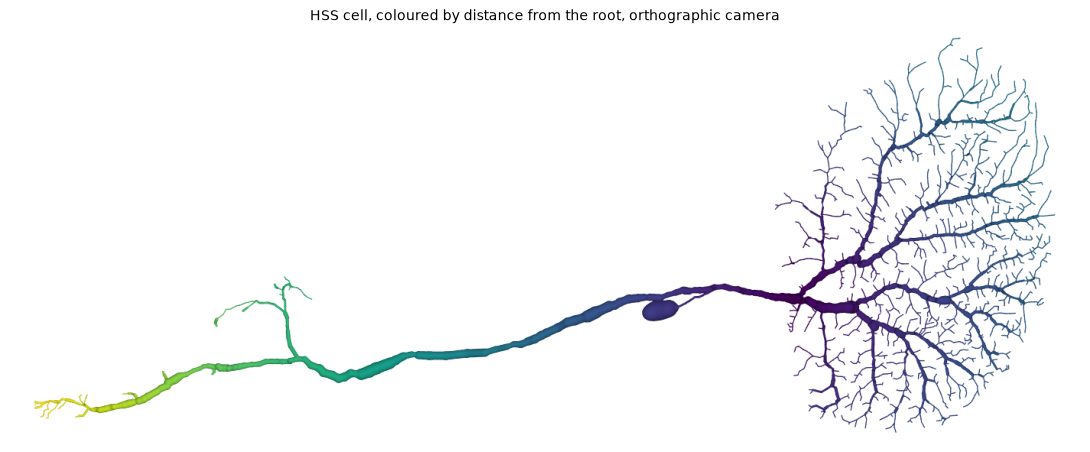

In [7]:
def orthographic_scene(cell, name, v, background="rgb 1",
                       finish="ambient 0.45 diffuse 0.55", pixels_wide=1400):
    "Export a cell, write an orthographic scene for it, and render it."
    pt.save_pov(cell, WORK / f"{name}.pov", style=None, v=v, minmax=True)

    points = np.column_stack([cell.X, cell.Y, cell.Z])
    low, high = points.min(axis=0), points.max(axis=0)
    centre = (low + high) / 2
    view_width, view_height = (high - low)[:2] * 1.05

    scene = WORK / f"{name}_scene.pov"
    scene.write_text(f'''
#version 3.7;
global_settings {{ assumed_gamma 2.2 }}
#default {{ finish {{ {finish} }} }}
#include "{name}.pov"

background {{ color {background} }}

camera {{
  orthographic
  location <{centre[0]:.2f}, {centre[1]:.2f}, {low[2] - 100:.2f}>
  look_at  <{centre[0]:.2f}, {centre[1]:.2f}, {low[2]:.2f}>
  right x * {view_width:.2f}
  up    y * {view_height:.2f}
}}

light_source {{ <{centre[0]:.2f}, {centre[1]:.2f}, {low[2] - 2000:.2f}> color rgb 1 shadowless }}

object {{ {name} }}
''')
    return povray(scene, pixels_wide, round(pixels_wide * view_height / view_width))


image = orthographic_scene(hss, "Hss", pt.eucl_tree(hss))
panel([image], ["HSS cell, coloured by distance from the root, orthographic camera"],
      width=11, save="tut09_pov_custom.png")

---

# Part 2: Blender

`pynetrees.blender` drives Blender through its `bpy` Python module, with no
window. It is not imported by `import pynetrees`, because it is a large and
restrictive dependency, so you ask for it explicitly.

`bpy` embeds **one Blender session per process**. Each call below clears the
objects in it first, but settings you change on the scene stay changed until you
change them back.

`bpy` also prints progress lines straight to the terminal, so `quiet` keeps them
out of the notebook.

In [8]:
import io
from contextlib import contextmanager, redirect_stdout

import bpy
from pynetrees import blender


@contextmanager
def quiet():
    "Silence bpy's output: progress lines bypass Python, reports do not."
    saved = [os.dup(1), os.dup(2)]
    null = os.open(os.devnull, os.O_WRONLY)
    os.dup2(null, 1)
    os.dup2(null, 2)
    try:
        with redirect_stdout(io.StringIO()):
            yield
    finally:
        os.dup2(saved[0], 1)
        os.dup2(saved[1], 2)
        for descriptor in (*saved, null):
            os.close(descriptor)


def render(cell, name, **options):
    "render_tree with its progress output silenced."
    with quiet():
        return blender.render_tree(cell, WORK / f"{name}.png", **options)


print("Blender", bpy.app.version_string)

Blender 5.0.1


## 2.1 One call, three views

`render_tree` builds the cell, frames it, lights it and renders. The camera is
orthographic and frames the bounding box, so the whole cell is in shot at any
image size. Pass `view=` to choose the plane.

Each region becomes its own object with its own colour, which is why the
`subtree` region stands out here.

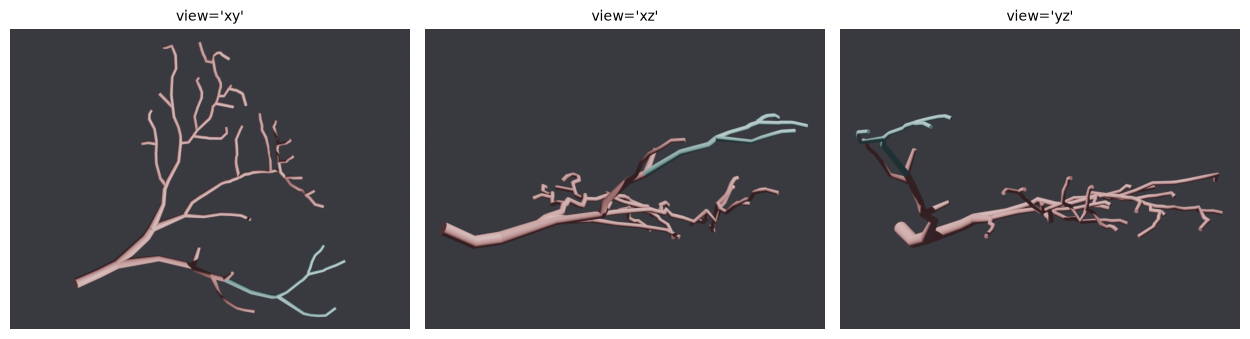

In [9]:
images = [render(tree, f"view_{v}", view=v, size=(800, 600)) for v in ("xy", "xz", "yz")]
panel(images, ["view='xy'", "view='xz'", "view='yz'"], save="tut09_blender_views.png")

## 2.2 Colours and diameters

Blender's default colour management is tuned for photographic images and washes
out flat colours, as the pale pink above shows. For a figure, switch it to
`Standard` so that the colour you ask for is the colour you get. This is the
scene setting that stays changed for the rest of the session.

`region_colors` sets the colour by region name. `taper=False` draws every branch
at the mean diameter, which can be easier to read in a schematic.

Blender's colours are linear, while matplotlib's and most colour pickers are
sRGB. `linear` converts between them.

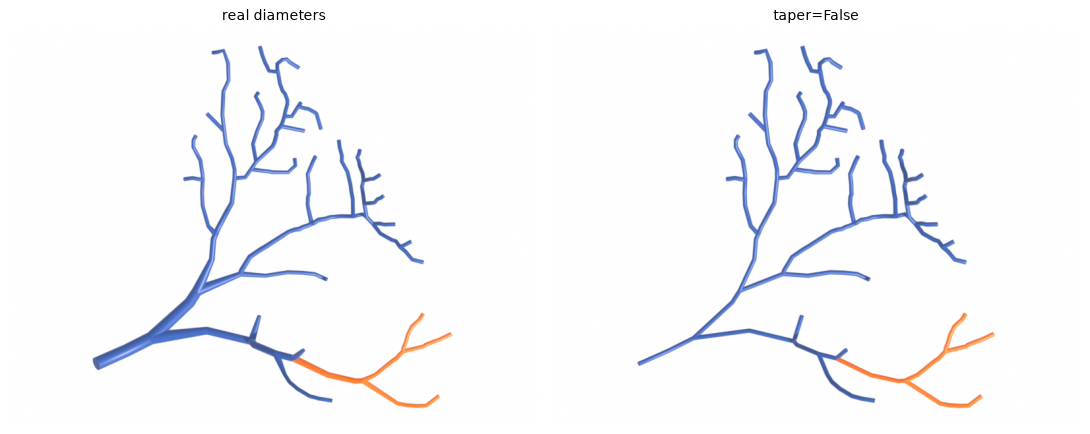

In [10]:
bpy.context.scene.view_settings.view_transform = "Standard"


def linear(rgb):
    "Convert an sRGB colour to the linear values Blender expects."
    return tuple(channel ** 2.2 for channel in rgb[:3])


palette = {"dendrite": linear((0.13, 0.27, 0.53)), "subtree": linear((0.84, 0.37, 0.0))}
figure = dict(background=(1, 1, 1), region_colors=palette, size=(800, 600))

images = [render(tree, "tapered", **figure),
          render(tree, "untapered", taper=False, **figure)]
panel(images, ["real diameters", "taper=False"], width=5.5, save="tut09_blender_colours.png")

## 2.3 Colouring by a measurement

Blender export colours by region, not by node. A measurement that is constant
along each section, such as branch order, can still be shown by making each
value its own region. The names are zero-padded because region colours are
matched by substring, so `order1` would also match `order10`.

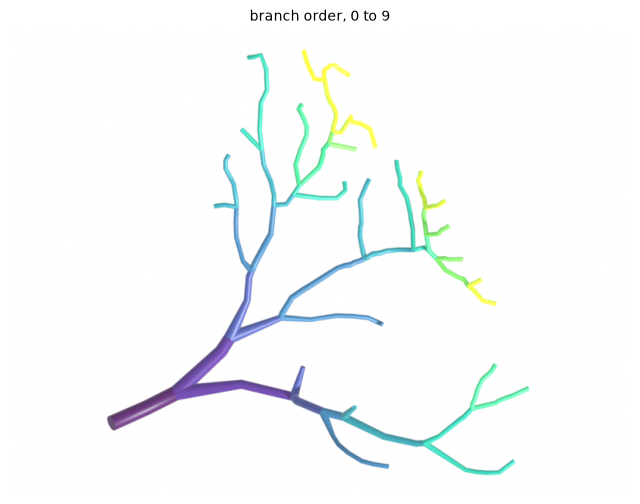

In [11]:
order = pt.BO_tree(tree).astype(int)
names = [f"order{k:02d}" for k in range(order.max() + 1)]
by_order = tree.copy(R=order, rnames=names, name="by_order")

viridis = plt.colormaps["viridis"].resampled(len(names))
colors = {name: linear(viridis(k)) for k, name in enumerate(names)}

image = render(by_order, "by_order", background=(1, 1, 1), region_colors=colors,
               size=(800, 600))
panel([image], [f"branch order, 0 to {order.max()}"], width=6.5,
      save="tut09_blender_order.png")

## 2.4 Several cells in one image

Pass a list of trees to render them into one scene. `spread_tree` lays them out
so that they do not overlap. Two options help at this scale: `resolution=` sets
how many sides each tube has, so a lower value keeps large populations quick,
and `min_diameter=` stops the finest branches from disappearing.

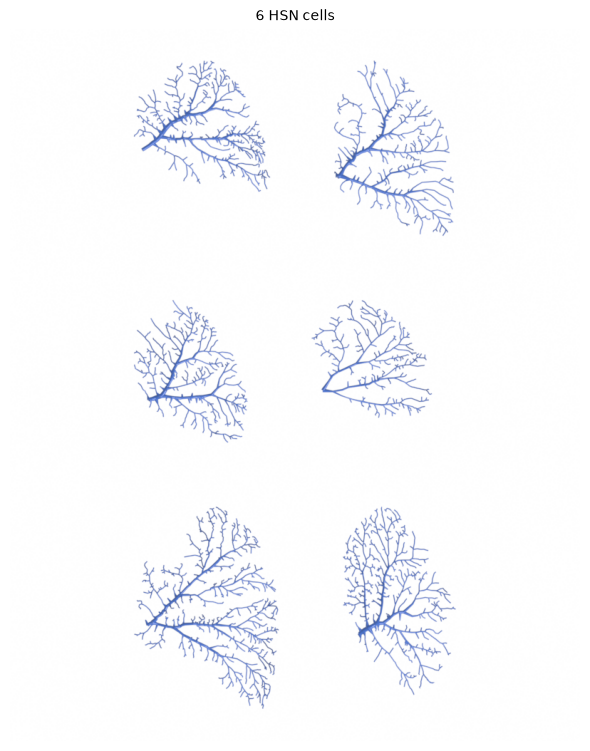

In [12]:
cells = pt.dLPTCs_trees()["dhsn"][:6]
spread = pt.spread_tree(cells, dx=150, dy=150)

blue = linear((0.13, 0.27, 0.53))
regions = {region: blue for cell in cells for region in cell.rnames}

image = render(spread.trees, "population", background=(1, 1, 1), resolution=3,
               min_diameter=2.5, region_colors=regions, size=(800, 1000))
panel([image], [f"{len(cells)} HSN cells"], width=6, save="tut09_blender_population.png")

## 2.5 Going further with `bpy`

`build_tree` stops once the objects exist and leaves the scene to you. From there
everything in Blender's Python API is available. This example builds the cell,
sits it above a floor, adds a perspective camera and a low sun, and uses Blender's
Cycles path-tracer for soft shadows.

A perspective camera makes near branches look thicker than far ones. That is
fine for an illustration, and is why `render_tree` does not use one.

sample_dendrite     46 splines, one per section
sample_subtree       5 splines, one per section


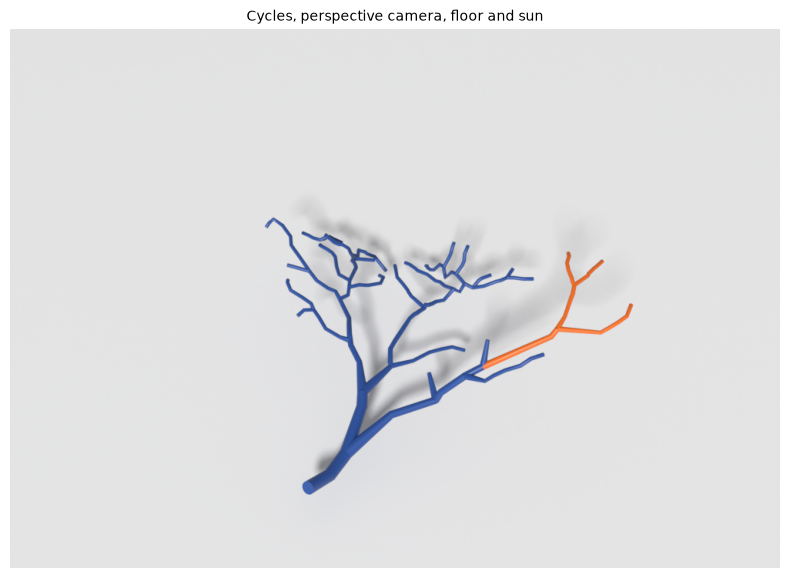

In [13]:
from mathutils import Vector

scene = bpy.context.scene
objects = blender.build_tree(tree, region_colors=palette, resolution=6)

for obj in objects:
    print(f"{obj.name:18s} {len(obj.data.splines):3d} splines, one per section")

points = np.column_stack([tree.X, tree.Y, tree.Z])
centre = Vector(((points.min(axis=0) + points.max(axis=0)) / 2).tolist())
span = float(np.ptp(points, axis=0).max())

# a floor just below the lowest point of the cell
bpy.ops.mesh.primitive_plane_add(
    size=span * 12, location=(centre.x, centre.y, float(points[:, 2].min()) - 8))

# the camera looks at the centre of the cell from one side and above
camera = bpy.data.objects.new("camera", bpy.data.cameras.new("camera"))
camera.data.lens = 60
camera.data.clip_end = span * 100
camera.location = centre + Vector((-0.9, -1.5, 1.6)) * (span * 1.55)
camera.rotation_euler = (centre - camera.location).to_track_quat("-Z", "Y").to_euler()
scene.collection.objects.link(camera)
scene.camera = camera

# a low sun gives soft shadows that fall away from the cell
sun = bpy.data.objects.new("sun", bpy.data.lights.new("sun", type="SUN"))
sun.data.energy = 4.0
sun.data.angle = math.radians(8)
sun.rotation_euler = (math.radians(58), 0, math.radians(-40))
scene.collection.objects.link(sun)

world = scene.world
world.node_tree.nodes["Background"].inputs["Color"].default_value = (0.8, 0.8, 0.82, 1)
world.node_tree.nodes["Background"].inputs["Strength"].default_value = 0.4

scene.render.engine = "CYCLES"
scene.cycles.samples = 64
scene.render.resolution_x, scene.render.resolution_y = 1000, 700
scene.render.filepath = str(WORK / "cycles.png")
with quiet():
    bpy.ops.render.render(write_still=True)

panel([WORK / "cycles.png"], ["Cycles, perspective camera, floor and sun"], width=8,
      save="tut09_blender_cycles.png")

## 2.6 Saving a `.blend`

`save_blend` writes the scene to a file you can open in Blender. Every region is
a real, selectable object, with its material and per-node diameters intact.

A `.blend` is for a figure, not for storing a morphology. Blender keeps
coordinates in single precision, so use `save_tree` for the data itself.

In [14]:
with quiet():
    path = blender.save_blend(tree, WORK / "sample_cell.blend")
    bpy.ops.wm.open_mainfile(filepath=str(path))

print(f"{path.name}: {path.stat().st_size / 1024:.0f} kB")
print("reopened, it contains:", [obj.name for obj in bpy.data.objects])

sample_cell.blend: 92 kB
reopened, it contains: ['sample_dendrite', 'sample_subtree']


---

# Part 3: Showcase

Five harder scenes, each taking a look from published neuron visualisation and
building it from what the toolbox already has. They use the granule-cell and
fly-interneuron datasets bundled with the package. The first four render in
seconds, and the last takes a few minutes.

The first two need only POV-Ray; the other three use Blender.

## 3.1 A Golgi stain

Golgi-stained sections show a few dark cells at different depths, some in focus
and some not. Blue Brain has built a
[physically based brightfield model](https://link.springer.com/article/10.1186/s12859-017-1788-4)
of this. The version here is an illustration of the look, using three things POV-Ray
provides: instancing, depth of field and procedural textures.

Each morphology is exported once and placed many times with `object { ... }`. The
`aperture` and `focal_point` lines add the depth of field, and the `bozo` pigment
and `bumps` normal make the paper.

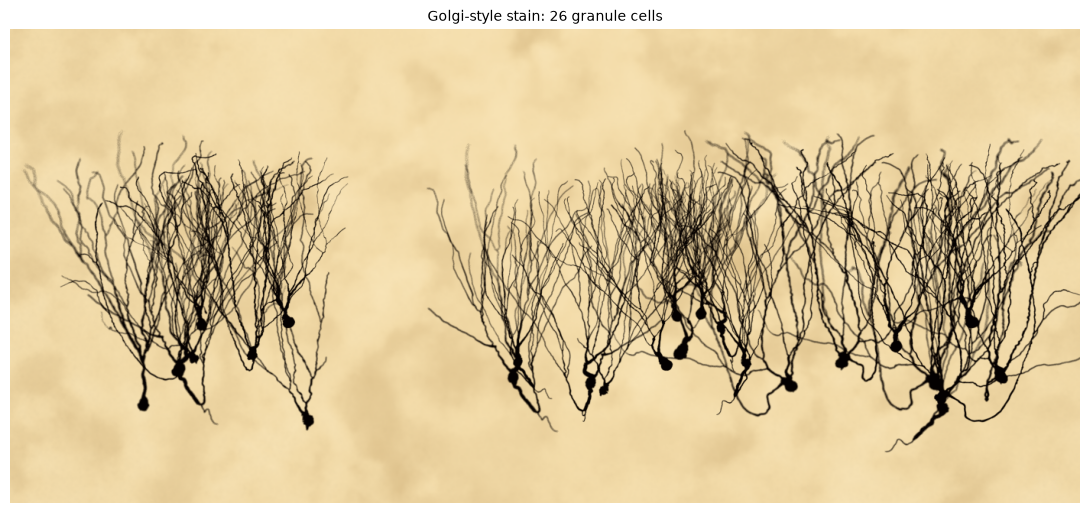

In [15]:
def granule_dendrites():
    "The bundled granule cells without their axons, each as a single region."
    cells = []
    for cell in pt.gc_trees():
        kept = pt.delete_tree(cell, np.flatnonzero(cell.region_nodes("axon", "axonh")))
        cells.append(kept.copy(R=np.zeros(kept.n_nodes, int), rnames=["cell"]))
    return cells


granule = granule_dendrites()
rng = np.random.default_rng(11)

includes = []
for index, cell in enumerate(granule):
    pt.save_pov(cell, WORK / f"Gc{index}.pov", style=None, blob=False,
                color=(0.05, 0.03, 0.02))
    includes.append(f'#include "Gc{index}.pov"')

placed = []
for _ in range(26):
    which = rng.integers(len(granule))
    spin, tilt = rng.uniform(0, 360), 90 + rng.normal(0, 7)
    x, y, z = rng.uniform(-420, 420), rng.normal(0, 14), rng.uniform(-150, 110)
    placed.append(f"object {{ Gc{which} rotate x*{spin:.1f} rotate z*{tilt:.1f} "
                  f"translate <{x:.1f}, {y:.1f}, {z:.1f}> }}")

newline = "\n"
(WORK / "Golgi.pov").write_text(f'''
#version 3.7;
global_settings {{ assumed_gamma 2.2 }}
#default {{ finish {{ ambient 0.9 diffuse 0.1 }} }}
{newline.join(includes)}

camera {{
  location <0, 70, -900>
  look_at  <0, 70, 0>
  right x * image_width / image_height
  angle 62
  aperture 26
  focal_point <0, 70, -20>
  blur_samples 40
  confidence 0.9
  variance 1 / 500
}}

light_source {{ <0, 200, -2000> color rgb 1 shadowless }}

plane {{ z, 260
  texture {{
    pigment {{
      bozo color_map {{
        [0   rgb <0.93, 0.86, 0.70>]
        [0.5 rgb <0.90, 0.81, 0.62>]
        [1   rgb <0.81, 0.70, 0.50>]
      }}
      scale 110 turbulence 1.1
    }}
    normal {{ bumps 0.35 scale 1.8 }}
    finish {{ ambient 0.78 diffuse 0.28 }}
  }}
}}

{newline.join(placed)}
''')

image = povray(WORK / "Golgi.pov", 1400, 620)
panel([image], [f"Golgi-style stain: {len(placed)} granule cells"], width=11,
      save="tut09_show_golgi.png")

## 3.2 A simulation on the morphology

A rendering can carry a result. Here `sse_tree` computes the steady-state voltage
everywhere for a current injected at the most distant dendritic tip, with no
simulator involved, and each segment is coloured by the logarithm of that voltage.
The signal is strong in the injected branch and fades quickly into the rest of the
tree.

1 nA at node 613: 116 mV at the tip, 38 mV at the root


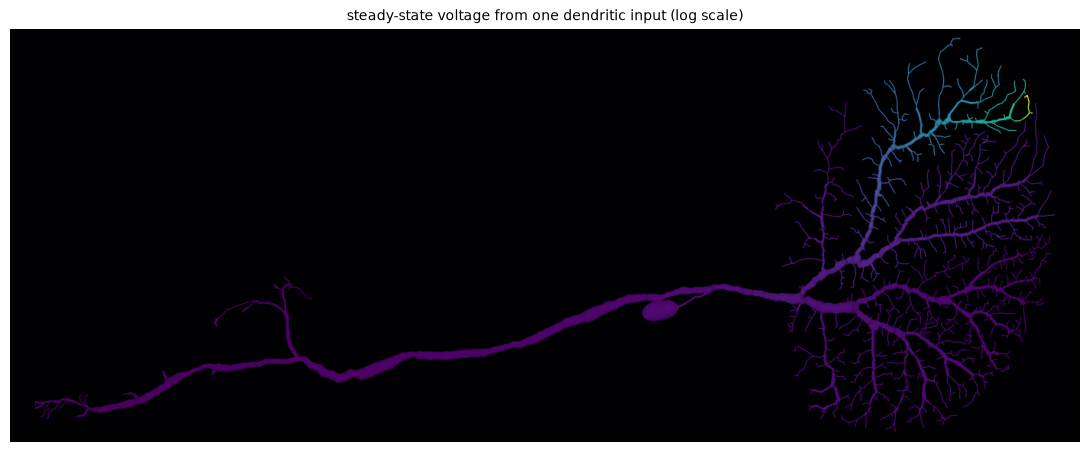

In [16]:
cell = hss.copy(Ri=100.0, Gm=1 / 20000, Cm=1.0)

tips = np.flatnonzero(pt.T_tree(cell) & cell.region_nodes("dend"))
distance = pt.Pvec_tree(cell, pt.len_tree(cell))
site = int(tips[np.argmax(distance[tips])])

voltage = pt.sse_tree(cell, I=site)
print(f"1 nA at node {site}: {voltage[site]:.0f} mV at the tip, "
      f"{voltage[cell.root]:.0f} mV at the root")

image = orthographic_scene(cell, "Attenuation", np.log10(voltage),
                           background="rgb <0.02, 0.02, 0.04>",
                           finish="ambient 0.8 diffuse 0.35")
panel([image], ["steady-state voltage from one dendritic input (log scale)"],
      width=11, save="tut09_show_attenuation.png")

## 3.3 A dense population

Connectome papers such as
[Janelia's optic-lobe inventory](https://www.nature.com/articles/s41586-025-08746-0)
use Blender and largely orthographic views to show many neurons at once. This scene
scatters 300 granule cells through a layer and gives each its own colour.

The 300 cells are random rotations of the 8 bundled morphologies. Each one is a
Blender object that shares its curve data with others of the same morphology, so
the scene stays light. Colour comes from each object's `color` property, read in the
shader by an **Object Info** node, so only one material is needed.

The helpers below are shared with the next section. `reset_scene` also deletes
materials, so it has to run before any are created.

In [17]:
def new_material():
    "A new material and its node tree."
    material = bpy.data.materials.new("cell")
    if not material.node_tree:
        material.use_nodes = True
    return material, material.node_tree


def granule_layer(material, n_cells=300, seed=4):
    "Scatter copies of the granule cells through a layer, dendrites pointing up."
    scene = bpy.context.scene
    rng = np.random.default_rng(seed)

    templates = []
    for index, cell in enumerate(granule):
        obj = blender.build_tree(cell, name=f"gc{index}", resolution=1,
                                 min_diameter=0.5, reset=False)[0]
        obj.data.materials[0] = material
        obj.hide_render = True
        templates.append(obj)

    layer = []
    for _ in range(n_cells):
        obj = templates[rng.integers(len(templates))].copy()   # shares the curve data
        obj.hide_render = False
        obj.location = rng.uniform(-450, 450), rng.normal(0, 8), rng.uniform(-120, 120)
        obj.rotation_euler = (rng.uniform(0, 2 * math.pi), rng.normal(0, 0.08),
                              math.pi / 2 + rng.normal(0, 0.12))
        scene.collection.objects.link(obj)
        layer.append(obj)
    return layer, rng


def look_from(location, target, **settings):
    "Add a camera at `location`, pointing at `target`."
    camera = bpy.data.objects.new("camera", bpy.data.cameras.new("camera"))
    camera.location = Vector(location)
    camera.rotation_euler = (Vector(target) - camera.location).to_track_quat("-Z", "Y").to_euler()
    camera.data.clip_end = 1e5
    for name, value in settings.items():
        setattr(camera.data, name, value)
    bpy.context.scene.collection.objects.link(camera)
    bpy.context.scene.camera = camera
    return camera


def backdrop(color, strength):
    "Set the colour and brightness of the world behind the scene."
    scene = bpy.context.scene
    scene.world = scene.world or bpy.data.worlds.new("world")
    if not scene.world.node_tree:
        scene.world.use_nodes = True
    node = scene.world.node_tree.nodes["Background"]
    node.inputs["Color"].default_value = (*color, 1)
    node.inputs["Strength"].default_value = strength


def cycles(name, size, samples):
    "Render the current scene with Cycles and return the image's path."
    scene = bpy.context.scene
    scene.render.engine = "CYCLES"
    scene.cycles.samples = samples
    scene.cycles.use_denoising = True
    scene.view_settings.view_transform = "Standard"
    scene.render.resolution_x, scene.render.resolution_y = size
    scene.render.filepath = str(WORK / f"{name}.png")
    with quiet():
        bpy.ops.render.render(write_still=True)
    return WORK / f"{name}.png"

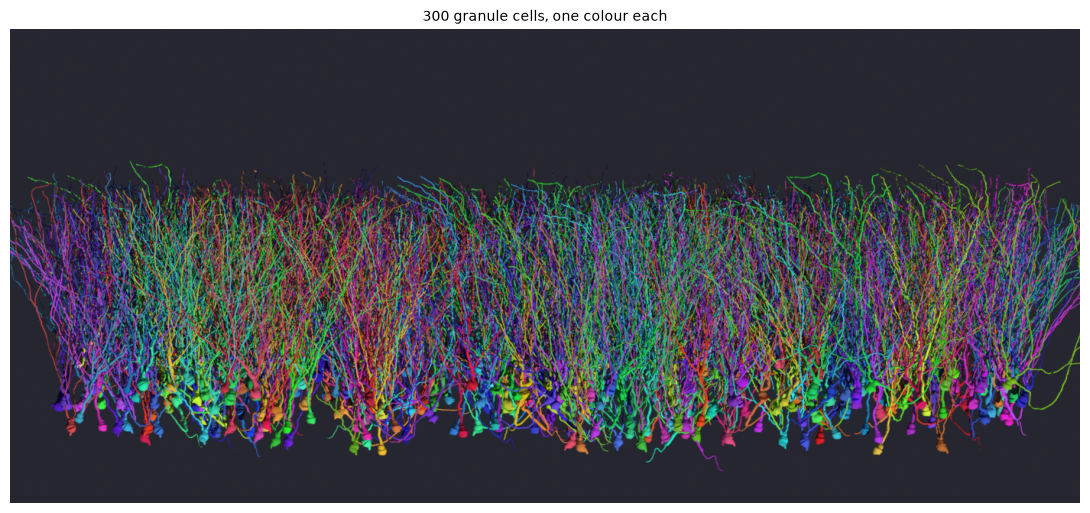

In [18]:
import colorsys

blender.reset_scene()
material, nodes = new_material()
surface = nodes.nodes["Principled BSDF"]
surface.inputs["Roughness"].default_value = 1.0
info = nodes.nodes.new("ShaderNodeObjectInfo")
nodes.links.new(info.outputs["Color"], surface.inputs["Base Color"])

layer, rng = granule_layer(material)
for obj in layer:
    hue, saturation, value = rng.random(), rng.uniform(0.65, 0.95), rng.uniform(0.75, 1)
    obj.color = (*linear(colorsys.hsv_to_rgb(hue, saturation, value)), 1)

sun = bpy.data.objects.new("sun", bpy.data.lights.new("sun", type="SUN"))
sun.data.energy = 3.0
sun.rotation_euler = (math.radians(35), math.radians(20), 0)
bpy.context.scene.collection.objects.link(sun)

backdrop((0.02, 0.02, 0.03), 1.0)
look_from((0, 100, 1500), (0, 100, 0), type="ORTHO", ortho_scale=1000)

image = cycles("population_dense", (1400, 620), 48)
panel([image], [f"{len(layer)} granule cells, one colour each"], width=11,
      save="tut09_show_population.png")

## 3.4 In-silico fluorescence

Sparse labelling makes a few cells bright against dim tissue, and a microscope keeps
only one plane in focus. Blue Brain's
[in-silico imaging](https://www.frontiersin.org/journals/neuroscience/articles/10.3389/fnins.2018.00664/full)
reproduces this with real tissue optics. This scene imitates the look only, with no
scattering, using the same layer as above.

The cells emit light instead of reflecting it. The shader raises each object's random
number to the 12th power, so most cells stay dim and a few are bright. In Blender's
units a cell is hundreds of metres wide, which is why the f-stop is so small.

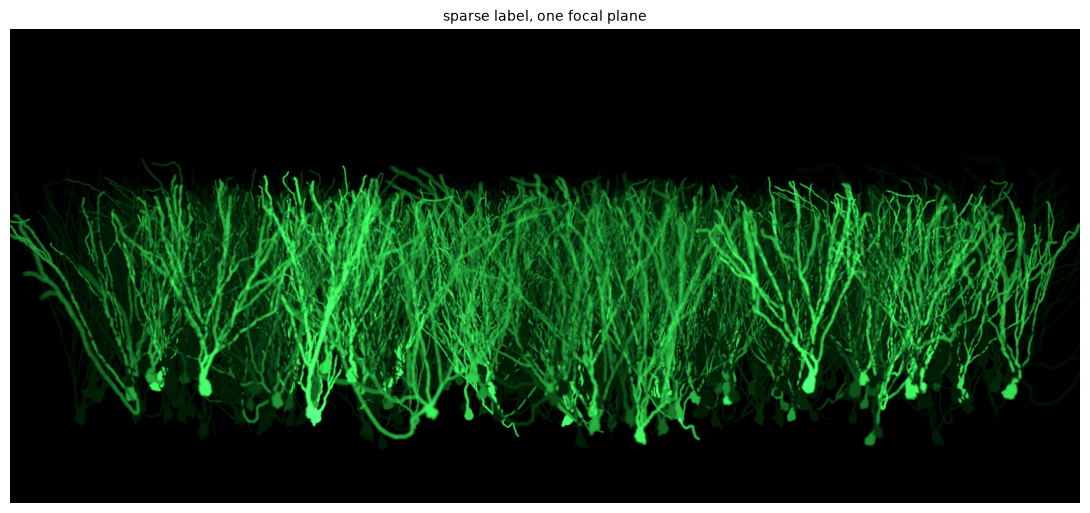

In [19]:
blender.reset_scene()
material, nodes = new_material()
for node in list(nodes.nodes):
    if node.type == "BSDF_PRINCIPLED":
        nodes.nodes.remove(node)
output = next(node for node in nodes.nodes if node.type == "OUTPUT_MATERIAL")

emission = nodes.nodes.new("ShaderNodeEmission")
emission.inputs["Color"].default_value = (0.05, 1, 0.12, 1)
nodes.links.new(emission.outputs[0], output.inputs["Surface"])

info = nodes.nodes.new("ShaderNodeObjectInfo")
sparse = nodes.nodes.new("ShaderNodeMath")
sparse.operation = "POWER"
sparse.inputs[1].default_value = 12
brightness = nodes.nodes.new("ShaderNodeMath")
brightness.operation = "MULTIPLY_ADD"
brightness.inputs[1].default_value = 2.2
brightness.inputs[2].default_value = 0.012
nodes.links.new(info.outputs["Random"], sparse.inputs[0])
nodes.links.new(sparse.outputs[0], brightness.inputs[0])
nodes.links.new(brightness.outputs[0], emission.inputs["Strength"])

granule_layer(material)
backdrop((0, 0, 0), 0)
camera = look_from((0, 95, 1500), (0, 95, 0), lens=50)
camera.data.dof.use_dof = True
camera.data.dof.focus_distance = 1500
camera.data.dof.aperture_fstop = 0.0012

image = cycles("fluorescence", (1400, 620), 128)
panel([image], ["sparse label, one focal plane"], width=11, save="tut09_show_fluorescence.png")

## 3.5 A spiny dendrite with a textured membrane

[NeuroMorphoVis](https://academic.oup.com/bioinformatics/article/34/13/i574/5045775)
and [its watertight spiny meshes](https://pmc.ncbi.nlm.nih.gov/articles/PMC11317524/)
make close-ups by joining an arbor and its spines into one closed surface. Voxel
remeshing does that in a few lines of Blender: every tube is sampled onto a fine
grid, and one surface is rebuilt around them.

The branch comes from `sample_tree`, with artificial spines, so this is a rendering
example and not a model of a real spiny dendrite. It is resampled first because
`spines_tree` attaches spines only at existing nodes.

In [20]:
_, branch = pt.sub_tree(pt.sample_tree(), 160)
branch = pt.resample_tree(branch.copy(D=np.maximum(branch.D, 1.2)), 0.5)
spiny = pt.spines_tree(branch, spines=int(2 * branch.total_length), neck_diameter=0.3,
                       head_diameter=0.9, neck_length=1.0, neck_length_std=0.3, rng=2)

blender.reset_scene()
objects = blender.build_tree(spiny, name="dendrite", resolution=4)

bpy.ops.object.select_all(action="DESELECT")
for obj in objects:
    obj.select_set(True)
bpy.context.view_layer.objects.active = objects[0]
with quiet():
    bpy.ops.object.convert(target="MESH")
    bpy.ops.object.join()
membrane = bpy.context.view_layer.objects.active

remesh = membrane.modifiers.new("remesh", "REMESH")
remesh.mode = "VOXEL"
remesh.voxel_size = 0.05       # [um], small enough to resolve the 0.3 um necks
remesh.use_smooth_shade = True
smooth = membrane.modifiers.new("smooth", "SMOOTH")
smooth.factor = 0.6
smooth.iterations = 10
with quiet():
    bpy.ops.object.modifier_apply(modifier="remesh")
    bpy.ops.object.modifier_apply(modifier="smooth")

print(f"{branch.total_length:.0f} um of cable and {int(2 * branch.total_length)} spines "
      f"became one surface of {len(membrane.data.polygons):,} faces")

185 um of cable and 370 spines became one surface of 1,206,160 faces


### The membrane texture

The texture is procedural, so it needs no image files and has no seams. It has
three layers of relief, added together and sent to the material's **Displacement**
output so that the surface really moves: slow undulations, a granular layer built
from a Voronoi pattern with a dome over each cell, and a fine roughness on top. The
colour varies in soft patches and darkens in the crevices between granules.

Two details matter here:

- **Texture coordinates.** Each texture is driven by **Object** coordinates, which
  are in micrometres in this scene. Left unconnected, Blender stretches a texture
  over the object's bounding box, and these features would be many micrometres wide.
- **The mean height is subtracted.** Otherwise the relief pushes everything outward
  and swells the thin necks until they disappear.

The relief is an illustration. Real membrane is much smoother at this scale.

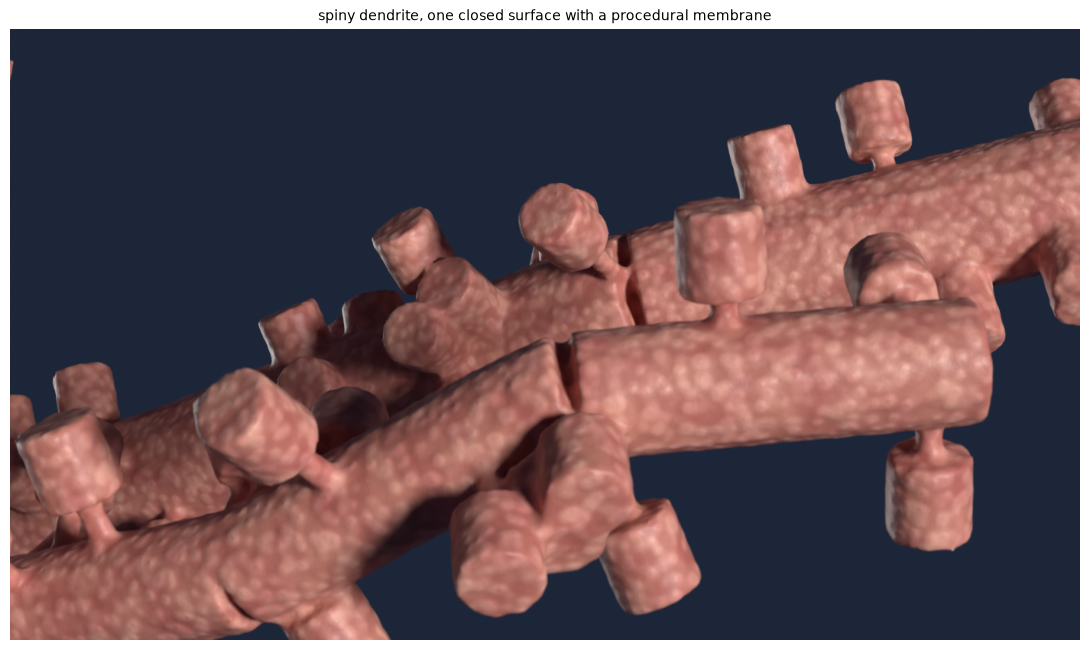

In [21]:
UNDULATION = 0.055   # height of the slow undulations [um]
GRANULE = 0.022      # height of the granules [um]
ROUGHNESS = 0.004    # height of the fine roughness [um]
GRANULES_PER_UM = 7  # Voronoi cells per micrometre

material, nodes = new_material()
surface = nodes.nodes["Principled BSDF"]
output = next(node for node in nodes.nodes if node.type == "OUTPUT_MATERIAL")
add, link = nodes.nodes.new, nodes.links.new
position = add("ShaderNodeTexCoord").outputs["Object"]


def noise(scale, detail):
    "A noise texture in micrometre coordinates."
    node = add("ShaderNodeTexNoise")
    link(position, node.inputs["Vector"])
    node.inputs["Scale"].default_value = scale
    node.inputs["Detail"].default_value = detail
    return node.outputs["Fac"]


def scaled(value, factor):
    node = add("ShaderNodeMath")
    node.operation = "MULTIPLY"
    link(value, node.inputs[0])
    node.inputs[1].default_value = factor
    return node.outputs[0]


def summed(first, second):
    node = add("ShaderNodeMath")
    link(first, node.inputs[0])
    link(second, node.inputs[1])
    return node.outputs[0]


# Distance to the nearest Voronoi point is low at a granule's centre and high in
# the crevice around it, so its negative is a dome over each granule.
cells = add("ShaderNodeTexVoronoi")
cells.feature = "SMOOTH_F1"
cells.inputs["Scale"].default_value = GRANULES_PER_UM
link(position, cells.inputs["Vector"])
crevice = cells.outputs["Distance"]

height = summed(summed(scaled(noise(1.1, 3), UNDULATION), scaled(crevice, -GRANULE)),
                scaled(noise(34, 5), ROUGHNESS))
displacement = add("ShaderNodeDisplacement")
link(height, displacement.inputs["Height"])
displacement.inputs["Scale"].default_value = 1.0
displacement.inputs["Midlevel"].default_value = (
    0.5 * UNDULATION - 0.3 * GRANULE + 0.5 * ROUGHNESS)   # the mean height
link(displacement.outputs[0], output.inputs["Displacement"])
material.displacement_method = "BOTH"

# colour: soft patches of two pinks, darker in the crevices
patches = add("ShaderNodeValToRGB")
link(noise(2.4, 6), patches.inputs["Fac"])
patches.color_ramp.elements[0].position = 0.32
patches.color_ramp.elements[0].color = (0.62, 0.22, 0.19, 1)
patches.color_ramp.elements[1].position = 0.68
patches.color_ramp.elements[1].color = (0.80, 0.40, 0.31, 1)

in_crevice = add("ShaderNodeMapRange")
link(crevice, in_crevice.inputs["Value"])
in_crevice.inputs["From Min"].default_value = 0.30
in_crevice.inputs["From Max"].default_value = 0.55

shaded = add("ShaderNodeMixRGB")
shaded.blend_type = "MULTIPLY"
link(in_crevice.outputs[0], shaded.inputs["Fac"])
link(patches.outputs["Color"], shaded.inputs["Color1"])
shaded.inputs["Color2"].default_value = (0.76, 0.62, 0.60, 1)
link(shaded.outputs["Color"], surface.inputs["Base Color"])

surface.inputs["Roughness"].default_value = 0.48
surface.inputs["Subsurface Weight"].default_value = 0.6
surface.inputs["Subsurface Radius"].default_value = (0.9, 0.35, 0.2)
surface.inputs["Subsurface Scale"].default_value = 0.08

membrane.data.materials.clear()
membrane.data.materials.append(material)

# aim at the middle of the branch, with a little depth of field
points = np.column_stack([branch.X, branch.Y, branch.Z])
target = points[np.argsort(points[:, 0])[len(points) // 2]]
distance = 34.0
location = Vector(target.tolist()) + Vector((-0.2, -0.8, 0.5)).normalized() * distance
camera = look_from(location, target.tolist(), lens=85, clip_start=0.01)
camera.data.dof.use_dof = True
camera.data.dof.focus_distance = distance
camera.data.dof.aperture_fstop = 1.0

backdrop((0.015, 0.025, 0.05), 0.8)
for angles, energy, softness in (((62, 8, 20), 3.6, 12), ((120, -20, 200), 1.2, 30)):
    sun = bpy.data.objects.new("sun", bpy.data.lights.new("sun", type="SUN"))
    sun.data.energy = energy
    sun.data.angle = math.radians(softness)
    sun.rotation_euler = [math.radians(angle) for angle in angles]
    bpy.context.scene.collection.objects.link(sun)

image = cycles("spiny", (1400, 800), 128)
panel([image], ["spiny dendrite, one closed surface with a procedural membrane"], width=11,
      save="tut09_show_spines.png")

---

## Which to use

- **A scripted figure, or colour by any value per node:** `save_pov`.
- **A view with no perspective:** `render_tree`, or `save_pov(style=None)` with an
  orthographic camera of your own (1.6).
- **A scene you will keep adjusting by hand:** `save_blend`.
- **A quick look without a renderer:** `plot_tree` or `plot_mpl_tree`, or
  `save_x3d` for a scene that opens in a browser.